# StericX for computational chemistry

This notebook calculates steric descriptors, examines six retained conformers, uses explicitly sourced MMFF energies, exports research tables, preserves failed inputs, integrates RDKit, and interprets the separate electron-density volume mode.

Use the locally built wheel or `python -m pip install './python[tables,rdkit,notebook]'` from the repository root. Then open this notebook from `python/examples/`. This development package is not published to PyPI. Coordinates are in Å; atom indices are zero-based. Molecular kernels retain their validated f32 behavior and ensemble reductions use f64.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import stericx as sx
from rdkit import Chem

DATA = Path("data").resolve()
OUTPUT = Path("notebook_output")
OUTPUT.mkdir(exist_ok=True)
print("StericX", sx.__version__)
print("Input manifest:", DATA / "manifest.json")

StericX 0.4.0.dev0
Input manifest: /run/media/andrej-rumenovski/New Volume/Code/StericX/python/examples/data/manifest.json


## Geometry, conventions and units

The ligand-401 inputs are copied from the retained repository MMFF94/ETKDGv3 study. Their hashes and source paths are in `data/manifest.json`. They are not asserted to be the historical Kraken geometries. Explicit coordination-axis Sterimol uses a virtual center-to-donor axis and the existing +0.40 Å L convention. The hard-sphere calculation uses R=3.5 Å, scale 1.17, H excluded from occupation, and a 2.28 Å center distance. Its `density` setting is nominal point volume in Å³, not grid spacing.

In [2]:
settings = json.loads((DATA / "ligand_401_options.json").read_text())
settings["volume"] = sx.VolumeOptions(**settings.get("volume", {}))
options = sx.DescriptorOptions(**settings)
molecule = sx.Molecule.from_file(DATA / "ligand_401_conformer_0.xyz")
d = molecule.descriptors(options)
print("Sterimol (Å):", d.sterimol.require())
print("Buried volume (Å³, %):", d.buried_volume.require().summary)
print(
    "Pyramidalization P (dimensionless), alpha (degrees):", d.pyramidalization.require()
)

Sterimol (Å): Sterimol(l=12.795559883117676, b1=3.2668983936309814, b5=6.595738887786865, unit='angstrom')
Buried volume (Å³, %): VolumeSummary(buried_volume=43.56204605102539, percent_buried_volume=24.255796432495117, qvbur_min=9.732691764831543, qvbur_max=13.532520294189453, max_delta_qvbur=3.79982852935791, ovbur_min=0.0, ovbur_max=13.532520294189453, near_vbur=43.562049865722656, far_vbur=0.0)
Pyramidalization P (dimensionless), alpha (degrees): Pyramidalization(pyr_p=0.9317666292190552, pyr_alpha=17.104389190673828)


## Individual conformers and arithmetic statistics

Every source record has an ordered index, original title, geometry, energy metadata and individual descriptor outcomes. Failures remain records. Arithmetic mean is sum/n; standard deviation uses divisor n; median is the central value or the mean of the two central values. Extrema retain all tied conformer identities. These describe the supplied finite ensemble, not conformational sampling completeness.

In [3]:
ensemble = sx.Ensemble.from_file(DATA / "ligand_401_ensemble.xyz")
unweighted = ensemble.descriptors(options, ligand_id="SIG-NIHDA-401")
assert unweighted.sterimol_b5.boltzmann_mean is None
print("Conformers:", len(ensemble))
print(
    "B5 mean/min/max/SD/median (Å):",
    unweighted.sterimol_b5.mean,
    unweighted.sterimol_b5.minimum,
    unweighted.sterimol_b5.maximum,
    unweighted.sterimol_b5.standard_deviation,
    unweighted.sterimol_b5.median,
)
unweighted.to_pandas()[
    [
        "conformer_index",
        "sterimol_l",
        "sterimol_b1",
        "sterimol_b5",
        "percent_buried_volume",
    ]
]

Conformers: 6
B5 mean/min/max/SD/median (Å): 7.713715235392253 6.595628261566162 8.87193775177002 1.1182278353747126 7.703705072402954


,conformer_index,sterimol_l,sterimol_b1,sterimol_b5,percent_buried_volume
0,0,12.795560,3.266898,6.595739,24.255796
1,1,12.730312,3.265108,6.595636,24.253633
2,2,12.730334,3.268869,6.595628,24.253633
3,3,10.371917,3.193257,8.871938,25.404554
4,4,10.085587,3.199789,8.811679,25.404554
5,5,10.085550,3.199592,8.811671,25.404554


## Explicit energy weighting

No energies are inferred from the XYZ comments or SDF property names. Here the original recorded relative MMFF94 energies are loaded with their units, model, provenance and unit multiplicities. The resulting weights are an energy-based approximation over retained states, not free-energy equilibrium populations or historical Kraken populations. Missing entropy, conformer-search completeness and degeneracy corrections are not supplied by this example.

Rust evaluates shifted log weights corresponding to `g_i exp[-(E_i-E_min)/(RT)]`, then normalizes them. Gibbs free energies require the declared evaluation temperature to match T. Supplying arbitrary normalized weights instead gives a weighted mean with explicit provenance, without labelling it Boltzmann.

In [4]:
energies = [
    sx.Energy(**row)
    for row in json.loads((DATA / "ligand_401_energies.json").read_text())
]
ensemble.set_energies(energies)
weighted = ensemble.descriptors(
    options,
    population=sx.Boltzmann(
        298.15,
        "Retained MMFF94 states, unit multiplicity; "
        "entropy and sampling completeness not established.",
    ),
    ligand_id="SIG-NIHDA-401",
)
pd.DataFrame(
    {
        "conformer_index": range(len(ensemble)),
        "recorded_relative_energy_kcal_mol": [e.value for e in energies],
        "energy_based_weight": weighted.population.weights,
    }
)

,conformer_index,recorded_relative_energy_kcal_mol,energy_based_weight
0,0,0.000000,0.262719
1,1,0.010076,0.258289
2,2,0.010076,0.258289
3,3,0.707178,0.079639
4,4,0.779124,0.070532
5,5,0.779124,0.070532


In [5]:
comparison = pd.DataFrame(
    {
        "summary": [
            "first conformer",
            "arithmetic mean",
            "MMFF energy-weighted mean",
            "minimum",
            "maximum",
        ],
        "B5_angstrom": [
            weighted.conformers[0].sterimol.require().b5,
            weighted.sterimol_b5.mean,
            weighted.sterimol_b5.boltzmann_mean,
            weighted.sterimol_b5.minimum,
            weighted.sterimol_b5.maximum,
        ],
    }
)
comparison

,summary,B5_angstrom
0,first conformer,6.595739
1,arithmetic mean,7.713715
2,MMFF energy-weighted mean,7.089549
3,minimum,6.595628
4,maximum,8.871938


## Conformer sensitivity without an arbitrary score

The range and standard deviation retain their physical units. The minimum and maximum report the responsible original conformers. An ensemble mean need not improve agreement with a historical target whose geometries, reduction and populations differ. The separate study in `docs/paton_recommendations/conformers/ENSEMBLE_STUDY.md` preserves all comparisons and demonstrates this limitation.

B5 range (Å): 2.2763094902038574
Minimum conformers: [2]
Maximum conformers: [3]


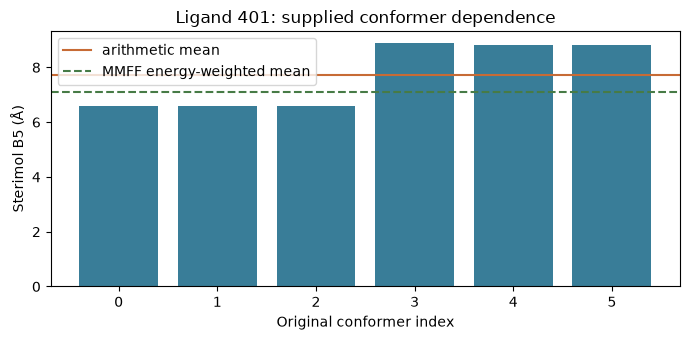

In [6]:
print("B5 range (Å):", weighted.sensitivity["ranges"]["sterimol_b5"])
print("Minimum conformers:", [c.index for c in weighted.sterimol_b5.minimum_conformers])
print("Maximum conformers:", [c.index for c in weighted.sterimol_b5.maximum_conformers])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(
    range(len(ensemble)),
    [c.sterimol.require().b5 for c in weighted.conformers],
    color="#397d98",
)
ax.axhline(weighted.sterimol_b5.mean, color="#c76b35", label="arithmetic mean")
ax.axhline(
    weighted.sterimol_b5.boltzmann_mean,
    color="#477b46",
    linestyle="--",
    label="MMFF energy-weighted mean",
)
ax.set(
    xlabel="Original conformer index",
    ylabel="Sterimol B5 (Å)",
    title="Ligand 401: supplied conformer dependence",
)
ax.legend()
fig.tight_layout()
plt.show()

## Export complete evidence and descriptor tables

The CSV is convenient for analysis, while JSON retains source geometries, options, provenance, regions, population assumptions and failed records. NumPy exports are structured arrays: unsuccessful numeric descriptors are NaN and explicit error columns remain alongside them. Do not silently drop these rows before modelling.

In [7]:
table = weighted.to_pandas()
table.to_csv(OUTPUT / "conformers.csv", index=False)
(OUTPUT / "ensemble.json").write_text(json.dumps(weighted.to_dict(), indent=2))
(OUTPUT / "sensitivity.csv").write_text(weighted.sensitivity_csv)
array = weighted.to_numpy()
print(array.dtype.names)
print("Files:", [p.name for p in sorted(OUTPUT.iterdir())])

('conformer_index', 'identifier', 'source', 'sterimol_l', 'sterimol_b1', 'sterimol_b5', 'buried_volume', 'percent_buried_volume', 'qvbur_min', 'qvbur_max', 'max_delta_qvbur', 'ovbur_min', 'ovbur_max', 'near_vbur', 'far_vbur', 'pyr_p', 'pyr_alpha', 'geometry_error', 'sterimol_error', 'buried_volume_error', 'pyramidalization_error', 'energy_error')
Files: ['conformers.csv', 'ensemble.json', 'sensitivity.csv']


## SDF correspondence and RDKit input

Regional bins are molecular-frame sectors and are not automatically aligned laboratory quadrants. XYZ does not supply authoritative adjacency, so regional ensemble statistics remain unavailable here even though every conformer's oriented regions are retained. A mapped SDF fixture supplies explicit bonds. The RDKit adapter uses existing conformers without embedding, optimizing, reordering or rounding through a four-decimal MOL representation. Matching element order and adjacency is still not proof of equal charge, bond order or stereochemical identity.

In [8]:
print("XYZ limitation:", weighted.regional_unavailable_reason)
mapped = sx.Ensemble.from_sdf(DATA / "mapped_ligand.sdf")
mapped_options = sx.DescriptorOptions(axis="coordination", donor_index=1)
mapped_result = mapped.descriptors(mapped_options)
print("Mapped regional statistic fields:", len(mapped_result.regions))
rdkit_molecule = Chem.MolFromMolFile(str(DATA / "mapped_ligand.sdf"), removeHs=False)
from_rdkit = sx.Molecule.from_rdkit(rdkit_molecule).descriptors(mapped_options)
assert from_rdkit.sterimol.require() == mapped_result.conformers[0].sterimol.require()
print("RDKit source identity:", from_rdkit.identifier, from_rdkit.properties)

XYZ limitation: regional statistics require complete matching element order and explicit adjacency; raw per-conformer regions remain available
Mapped regional statistic fields: 36
RDKit source identity:  ({'name': 'STERICX_RDKIT_CONFORMER_ID', 'value': '0'},)


## Batch processing and explicit failures

Batch results preserve file order. An unreadable file remains a failed item; a malformed conformer remains within its input ensemble. Default statistics require complete successful values for each descriptor. `missing="available_cases"` explicitly requests conditional subset statistics and reports missing identities and retained population mass.

In [9]:
batch = sx.calculate_files(
    [
        DATA / "ligand_401_conformer_0.xyz",
        DATA / "missing.xyz",
        DATA / "ligand_401_conformer_1.xyz",
    ],
    options,
    threads=2,
)
pd.DataFrame(
    {
        "path": [Path(item.path).name for item in batch],
        "conformers": [len(item.conformers) for item in batch],
        "error": [item.error.message if item.error else None for item in batch],
    }
)

,path,conformers,error
0,ligand_401_conformer_0.xyz,1,NaN
1,missing.xyz,0,No such file or directory (os error 2)
2,ligand_401_conformer_1.xyz,1,NaN


## Buried-volume radius profiles

The scan changes the evaluation sphere radius about a fixed center. It does not move the center along a bond. Hard-sphere profiles preserve the existing finite-grid method. Native and DBSTEP f32/f64 sphere-boundary handling differs at the included 2.5 Å witness; this documented numerical integration difference is not hidden by the API. Invalid finite radii remain individual errors.

In [10]:
hard_profile = molecule.buried_volume_scan([2.5, 3.5, 4.5, -1.0], options=options)
pd.DataFrame(
    {
        "requested_radius_A": [
            s.requested_radius_angstrom for s in hard_profile.samples
        ],
        "evaluated_radius_A": [
            s.evaluated_radius_angstrom for s in hard_profile.samples
        ],
        "buried_percent": [
            s.outcome.value.summary.percent_buried_volume
            if s.outcome.successful
            else None
            for s in hard_profile.samples
        ],
        "error": [
            s.outcome.error.message if s.outcome.error else None
            for s in hard_profile.samples
        ],
    }
)

,requested_radius_A,evaluated_radius_A,buried_percent,error
0,2.5,2.5,25.103325,NaN
1,3.5,3.5,24.255796,NaN
2,4.5,4.5,23.398363,NaN
3,-1.0,NaN,NaN,radius must be positive and representable as a...


## Electron-density mode is a different descriptor

The provided Ne cube is the unmodified official DBSTEP total-SCF-density fixture, with its license and source hash. The original quantum method is unspecified; none is invented. Occupation is strictly `density > threshold`, within a sphere whose nodes satisfy distance ≤ R. Grid buried volume is occupied-node count times cell volume; percent is the ratio of occupied to sampled sphere nodes. This differs from the hard-sphere analytic-sphere normalization.

The explicit 0.0016 electrons/Bohr³ threshold follows a documented convention, supported in a particular surface study by [Alibakhshi and Schäfer (2024)](https://doi.org/10.1038/s41467-024-50408-8). It is not a universal physical constant. Current support requires positive isotropic axis-aligned cube grids and complete sphere coverage; no padding or interpolation is performed. Native conversion is CODATA 2022, 0.529177210544 Å/Bohr. See `docs/methods/electron_density_buried_volume.md` and `docs/validation/dbstep/DENSITY_RESULTS.md` for definitions and independent admission.

In [11]:
density = sx.DensityGrid.from_cube(
    DATA / "Ne_medium.cube",
    field="total_electron_density",
    density_unit="electrons_per_bohr_cubed",
    provenance=(
        "Official DBSTEP Ne total-SCF-density fixture; "
        "original quantum method unspecified"
    ),
)
density_profile = density.buried_volume_scan(
    [1.0, 1.5, 2.0, 3.5],
    center_angstrom=(0.0, 0.0, 0.0),
    threshold_electrons_per_bohr3=0.0016,
)
pd.DataFrame(
    {
        "radius_A": [s.requested_radius_angstrom for s in density_profile.samples],
        "occupied_nodes": [
            s.outcome.value.occupied_nodes if s.outcome.successful else None
            for s in density_profile.samples
        ],
        "sphere_nodes": [
            s.outcome.value.sphere_nodes if s.outcome.successful else None
            for s in density_profile.samples
        ],
        "grid_volume_A3": [
            s.outcome.value.buried_volume_angstrom3 if s.outcome.successful else None
            for s in density_profile.samples
        ],
        "buried_percent": [
            s.outcome.value.percent_buried_volume if s.outcome.successful else None
            for s in density_profile.samples
        ],
        "error": [
            s.outcome.error.message if s.outcome.error else None
            for s in density_profile.samples
        ],
    }
)

,radius_A,occupied_nodes,sphere_nodes,grid_volume_A3,buried_percent,error
0,1.0,6100.0,6100.0,4.184871,100.000000,NaN
1,1.5,19726.0,20603.0,13.532913,95.743338,NaN
2,2.0,19726.0,48797.0,13.532913,40.424616,NaN
3,3.5,NaN,NaN,NaN,NaN,sphere extends outside density grid on axis 0;...


## Interpretation limits

These examples demonstrate reproducible descriptor calculations and explicit ensemble assumptions. They do not establish complete conformational sampling, experimental equilibrium populations, historical Kraken reproduction, a universal density threshold, or predictive catalyst performance. Default B1 uses a finite angular scan, and finite volume grids have boundary and orientation dependence. Independent numerical agreement, convergence and physical interpretation are separate questions. Retain failed comparisons, source geometries, settings and energy provenance when exporting research data.